In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

XAI_DIR = "/content/drive/MyDrive/VocaTrust/Explainable_AI"

os.makedirs(XAI_DIR, exist_ok=True)

print("XAI folder created successfully!")
print(XAI_DIR)

XAI folder created successfully!
/content/drive/MyDrive/VocaTrust/Explainable_AI


In [ ]:
import os

folders = [
    "Metadata",
    "ScoreCAM/Heatmaps",
    "ScoreCAM/Results",
    "Selected_Samples"
]

for folder in folders:
    os.makedirs(
        os.path.join(XAI_DIR, folder),
        exist_ok=True
    )

print("All Explainable AI folders are ready!")

All Explainable AI folders are ready!


In [ ]:
import shutil
import os

# Source: existing metadata file
SOURCE_METADATA = (
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2/Metadata/test_metadata.csv"
)

# Destination: Explainable AI folder
DEST_METADATA = (
    "/content/drive/MyDrive/VocaTrust/"
    "Explainable_AI/Metadata/test_metadata.csv"
)

# Copy without changing the original file
#shutil.copy2(SOURCE_METADATA, DEST_METADATA)

#print("✅ test_metadata.csv copied successfully!")
#print("Saved at:")
#print(DEST_METADATA)

In [ ]:
import pandas as pd

test_metadata = pd.read_csv(DEST_METADATA)

print("Metadata shape:", test_metadata.shape)
display(test_metadata.head())

Metadata shape: (22692, 4)


,Sample_ID,Language,GroundTruth,Dataset
0,101659,Hindi,REAL,Test
1,8496,English,REAL,Test
2,63920,English,REAL,Test
3,55963,English,REAL,Test
4,44130,English,FAKE,Test


In [ ]:
import numpy as np
import pandas as pd

# ============================================================
# LOAD MULTILINGUAL TEST DATA
# ============================================================

SPLIT_DIR = (
    "/content/drive/MyDrive/VocaTrust/"
    "Phase6_Multilingual/Combined/Train_Test_Split"
)

X_test = np.load(
    f"{SPLIT_DIR}/X_test.npy"
)

y_test = np.load(
    f"{SPLIT_DIR}/y_test.npy"
)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nMetadata rows:", len(test_metadata))

print(
    "\nSample count matches:",
    len(X_test) == len(test_metadata)
)

X_test shape: (22692, 39, 100, 1)
y_test shape: (22692,)

Metadata rows: 22692

Sample count matches: True


In [ ]:
# ============================================================
# VERIFY METADATA LABELS MATCH y_test
# ============================================================

# Convert GroundTruth to numeric labels
# REAL = 1
# FAKE = 0

metadata_labels = test_metadata["GroundTruth"].map({
    "REAL": 1,
    "FAKE": 0
}).to_numpy()

# Compare metadata labels with actual y_test
labels_match = np.array_equal(
    metadata_labels,
    y_test
)

print("Metadata labels shape:", metadata_labels.shape)
print("y_test shape          :", y_test.shape)

print("\nLabels match exactly:", labels_match)

# Show first 10 samples for manual verification
verification_df = pd.DataFrame({
    "Index": range(10),
    "Sample_ID": test_metadata["Sample_ID"].iloc[:10],
    "Language": test_metadata["Language"].iloc[:10],
    "Metadata_Label": metadata_labels[:10],
    "y_test": y_test[:10]
})

display(verification_df)

Metadata labels shape: (22692,)
y_test shape          : (22692,)

Labels match exactly: True


,Index,Sample_ID,Language,Metadata_Label,y_test
0,0,101659,Hindi,1,1
1,1,8496,English,1,1
2,2,63920,English,1,1
3,3,55963,English,1,1
4,4,44130,English,0,0
5,5,12629,English,1,1
6,6,15573,English,1,1
7,7,99181,Hindi,1,1
8,8,10396,English,1,1
9,9,54216,English,1,1


In [ ]:
from tensorflow.keras.models import load_model

# ============================================================
# LOAD FINAL MULTILINGUAL VOCATRUST MODEL
# ============================================================

MODEL_PATH = (
    "/content/drive/MyDrive/VocaTrust/"
    "Phase6_Multilingual/Models/"
    "VocaTrust_Multilingual_Final.keras"
)

model = load_model(MODEL_PATH)

print("✅ VocaTrust Multilingual Final Model loaded successfully!")

# Display model architecture
model.summary()

✅ VocaTrust Multilingual Final Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 39, 100, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 39, 100, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 19, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 19, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 19, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 9, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 25, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 9, 25, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6144)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       786,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,639,877 (10.07 MB)

 Trainable params: 879,809 (3.36 MB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 1,759,620 (6.71 MB)

In [ ]:
# ============================================================
# PREDICT ALL MULTILINGUAL TEST SAMPLES
# ============================================================

import numpy as np

print("Predicting all test samples...")

probabilities = model.predict(
    X_test,
    batch_size=64,
    verbose=1
).flatten()

# Convert probabilities to predictions
predictions = (probabilities >= 0.5).astype(int)

print("\nPrediction completed!")

print("Total predictions:", len(predictions))
print("Predictions shape:", predictions.shape)

Predicting all test samples...
355/355 ━━━━━━━━━━━━━━━━━━━━ 63s 173ms/step

Prediction completed!
Total predictions: 22692
Predictions shape: (22692,)


In [ ]:
# ============================================================
# CREATE XAI RESULTS TABLE
# ============================================================

xai_metadata = test_metadata.copy()

# Predicted numeric label
xai_metadata["Predicted_Label"] = predictions

# Probability of REAL from sigmoid output
xai_metadata["Probability_REAL"] = probabilities

# Convert prediction to text
xai_metadata["Prediction"] = np.where(
    predictions == 1,
    "REAL",
    "FAKE"
)

# Check whether prediction is correct
xai_metadata["Correct"] = (
    predictions == y_test
)

print("XAI metadata created!")

print("\nTotal samples:", len(xai_metadata))
print("Correct predictions:", xai_metadata["Correct"].sum())
print("Incorrect predictions:", (~xai_metadata["Correct"]).sum())

display(xai_metadata.head(20))

XAI metadata created!

Total samples: 22692
Correct predictions: 22501
Incorrect predictions: 191


,Sample_ID,Language,GroundTruth,Dataset,Predicted_Label,Probability_REAL,Prediction,Correct
0,101659,Hindi,REAL,Test,1,9.997984e-01,REAL,True
1,8496,English,REAL,Test,1,1.000000e+00,REAL,True
2,63920,English,REAL,Test,1,9.998172e-01,REAL,True
3,55963,English,REAL,Test,1,9.997997e-01,REAL,True
4,44130,English,FAKE,Test,0,1.936124e-06,FAKE,True
5,12629,English,REAL,Test,1,1.000000e+00,REAL,True
6,15573,English,REAL,Test,1,9.999990e-01,REAL,True
7,99181,Hindi,REAL,Test,1,9.996229e-01,REAL,True
8,10396,English,REAL,Test,1,9.999983e-01,REAL,True
9,54216,English,REAL,Test,1,9.809499e-01,REAL,True


In [ ]:
# ============================================================
# SELECT REPRESENTATIVE CORRECTLY CLASSIFIED SAMPLES
# ============================================================

correct_samples = xai_metadata[
    xai_metadata["Correct"] == True
].copy()

# English REAL
english_real = correct_samples[
    (correct_samples["Language"] == "English") &
    (correct_samples["GroundTruth"] == "REAL")
].sort_values(
    "Probability_REAL",
    ascending=False
).iloc[0]

# English FAKE
english_fake = correct_samples[
    (correct_samples["Language"] == "English") &
    (correct_samples["GroundTruth"] == "FAKE")
].sort_values(
    "Probability_REAL",
    ascending=True
).iloc[0]

# Hindi REAL
hindi_real = correct_samples[
    (correct_samples["Language"] == "Hindi") &
    (correct_samples["GroundTruth"] == "REAL")
].sort_values(
    "Probability_REAL",
    ascending=False
).iloc[0]

# Hindi FAKE
hindi_fake = correct_samples[
    (correct_samples["Language"] == "Hindi") &
    (correct_samples["GroundTruth"] == "FAKE")
].sort_values(
    "Probability_REAL",
    ascending=True
).iloc[0]

selected_samples = pd.DataFrame([
    english_real,
    english_fake,
    hindi_real,
    hindi_fake
])

display(
    selected_samples[
        [
            "Sample_ID",
            "Language",
            "GroundTruth",
            "Prediction",
            "Probability_REAL"
        ]
    ]
)

,Sample_ID,Language,GroundTruth,Prediction,Probability_REAL
22685,2739,English,REAL,REAL,1.000000e+00
16787,40314,English,FAKE,FAKE,1.314841e-23
22449,98158,Hindi,REAL,REAL,1.000000e+00
2298,104028,Hindi,FAKE,FAKE,7.712635e-19


ENGLISH REAL

In [ ]:
# ============================================================
# SELECT FIRST SAMPLE FOR SCORE-CAM
# ============================================================

sample_index = 22685

sample_x = X_test[sample_index:sample_index + 1]
sample_y = y_test[sample_index]

sample_info = xai_metadata.iloc[sample_index]

print("========================================")
print("SELECTED SAMPLE FOR SCORE-CAM")
print("========================================")

print("Test Index   :", sample_index)
print("Sample ID    :", sample_info["Sample_ID"])
print("Language     :", sample_info["Language"])
print("Ground Truth :", sample_info["GroundTruth"])
print("Prediction   :", sample_info["Prediction"])
print("Probability REAL :", sample_info["Probability_REAL"])

print("\nFeature shape:", sample_x.shape)
print("Actual label :", sample_y)

SELECTED SAMPLE FOR SCORE-CAM
Test Index   : 22685
Sample ID    : 2739
Language     : English
Ground Truth : REAL
Prediction   : REAL
Probability REAL : 1.0

Feature shape: (1, 39, 100, 1)
Actual label : 1


In [ ]:
# ============================================================
# CHECK CNN LAYER NAMES
# ============================================================

for i, layer in enumerate(model.layers):
    print(i, ":", layer.name, "→", layer.output.shape)

0 : conv2d → (None, 39, 100, 32)
1 : batch_normalization → (None, 39, 100, 32)
2 : max_pooling2d → (None, 19, 50, 32)
3 : dropout → (None, 19, 50, 32)
4 : conv2d_1 → (None, 19, 50, 64)
5 : batch_normalization_1 → (None, 19, 50, 64)
6 : max_pooling2d_1 → (None, 9, 25, 64)
7 : dropout_1 → (None, 9, 25, 64)
8 : conv2d_2 → (None, 9, 25, 128)
9 : batch_normalization_2 → (None, 9, 25, 128)
10 : max_pooling2d_2 → (None, 4, 12, 128)
11 : dropout_2 → (None, 4, 12, 128)
12 : flatten → (None, 6144)
13 : dense → (None, 128)
14 : dropout_3 → (None, 128)
15 : dense_1 → (None, 1)


In [ ]:
# ============================================================
# SCORE-CAM FOR VOCATRUST CNN
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


def score_cam(
    model,
    input_data,
    target_layer_name="conv2d_2",
    target_class=None
):

    # --------------------------------------------------------
    # 1. Create a model that gives the target convolution
    #    layer output
    # --------------------------------------------------------

    activation_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=model.get_layer(target_layer_name).output
    )

    # Get activation maps
    activations = activation_model(input_data)

    # Shape: (1, 9, 25, 128)
    activations = activations.numpy()[0]


    # --------------------------------------------------------
    # 2. Get original prediction
    # --------------------------------------------------------

    original_prediction = float(
        model.predict(input_data, verbose=0)[0][0]
    )


    # For binary classification:
    # REAL = 1
    # FAKE = 0

    if target_class is None:

        if original_prediction >= 0.5:
            target_class = 1
        else:
            target_class = 0


    # --------------------------------------------------------
    # 3. Calculate importance score for each feature map
    # --------------------------------------------------------

    scores = []

    height = input_data.shape[1]
    width = input_data.shape[2]

    for i in range(activations.shape[-1]):

        activation_map = activations[:, :, i]


        # Normalize activation map
        min_val = activation_map.min()
        max_val = activation_map.max()

        if max_val - min_val == 0:
            scores.append(0)
            continue

        normalized_map = (
            activation_map - min_val
        ) / (
            max_val - min_val
        )


        # Resize activation map to input size
        resized_map = tf.image.resize(
            normalized_map[..., np.newaxis],
            (height, width)
        ).numpy()

        resized_map = resized_map[:, :, 0]


        # Create masked input
        masked_input = (
            input_data[0] *
            resized_map[:, :, np.newaxis]
        )

        masked_input = np.expand_dims(
            masked_input,
            axis=0
        ).astype(np.float32)


        # Get prediction for masked input
        prediction = float(
            model.predict(
                masked_input,
                verbose=0
            )[0][0]
        )


        # Score according to target class
        if target_class == 1:
            score = prediction

        else:
            score = 1 - prediction

        scores.append(score)


    scores = np.array(scores)


    # --------------------------------------------------------
    # 4. Apply ReLU to scores
    # --------------------------------------------------------

    scores = np.maximum(scores, 0)


    # --------------------------------------------------------
    # 5. Normalize scores
    # --------------------------------------------------------

    if scores.max() != 0:
        scores = scores / scores.max()


    # --------------------------------------------------------
    # 6. Create weighted combination of activation maps
    # --------------------------------------------------------

    cam = np.zeros(
        activations.shape[:2],
        dtype=np.float32
    )

    for i in range(
        activations.shape[-1]
    ):

        cam += scores[i] * activations[:, :, i]


    # --------------------------------------------------------
    # 7. Apply ReLU
    # --------------------------------------------------------

    cam = np.maximum(cam, 0)


    # --------------------------------------------------------
    # 8. Normalize final CAM
    # --------------------------------------------------------

    if cam.max() != 0:
        cam = cam / cam.max()


    # --------------------------------------------------------
    # 9. Resize CAM to original feature size
    # --------------------------------------------------------

    cam_resized = tf.image.resize(
        cam[..., np.newaxis],
        (height, width)
    ).numpy()

    cam_resized = cam_resized[:, :, 0]


    return cam_resized, original_prediction, target_class

In [ ]:
# ============================================================
# GENERATE SCORE-CAM
# ============================================================

heatmap, prediction, target_class = score_cam(
    model=model,
    input_data=sample_x,
    target_layer_name="conv2d_2"
)

print("Original prediction:", prediction)
print("Target class:", "REAL" if target_class == 1 else "FAKE")

print("Heatmap shape:", heatmap.shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 39, 100, 1))
  warnings.warn(msg)


Original prediction: 1.0
Target class: REAL
Heatmap shape: (39, 100)


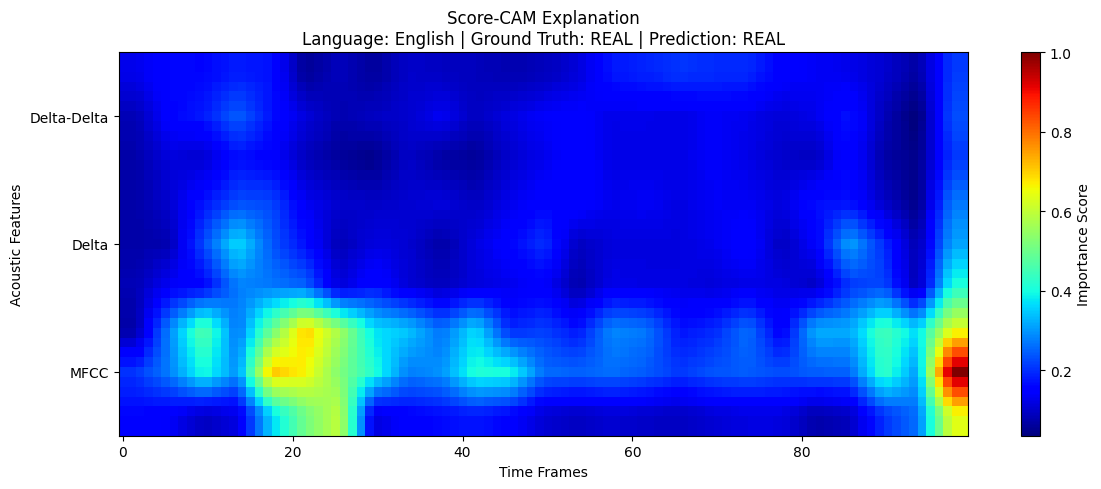

In [ ]:
# ============================================================
# VISUALIZE SCORE-CAM HEATMAP
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap,
    aspect="auto",
    cmap="jet",
    origin="lower"
)

plt.colorbar(label="Importance Score")

plt.title(
    f"Score-CAM Explanation\n"
    f"Language: {sample_info['Language']} | "
    f"Ground Truth: {sample_info['GroundTruth']} | "
    f"Prediction: {sample_info['Prediction']}"
)

plt.xlabel("Time Frames")

plt.ylabel("Acoustic Features")

plt.yticks(
    [6, 19, 32],
    ["MFCC", "Delta", "Delta-Delta"]
)

plt.tight_layout()
plt.show()

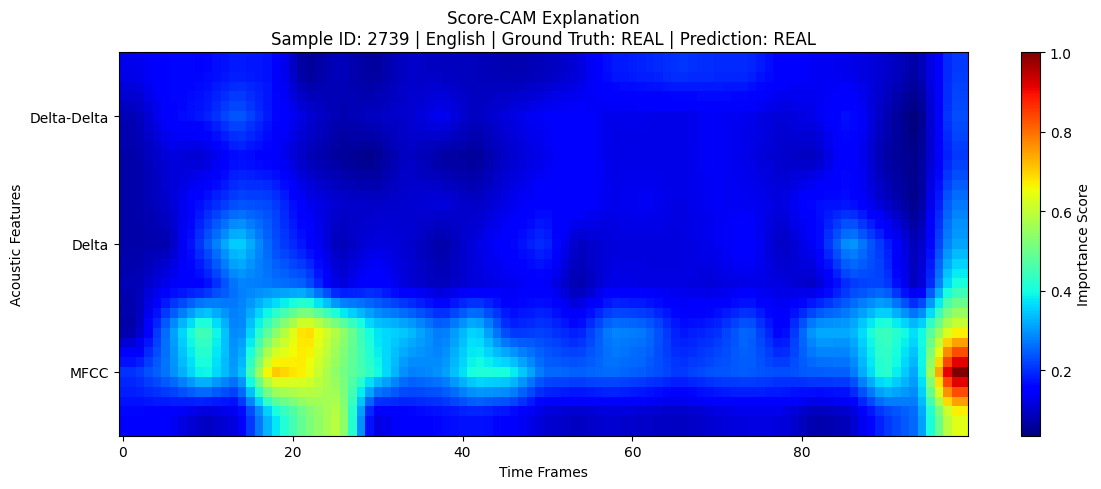

✅ Score-CAM heatmap saved successfully!
/content/drive/MyDrive/VocaTrust/Explainable_AI/ScoreCAM/Heatmaps/English_REAL_Sample2739_ScoreCAM.png


In [ ]:
# ============================================================
# SAVE ENGLISH REAL SCORE-CAM HEATMAP
# ============================================================

import os
import matplotlib.pyplot as plt

HEATMAP_DIR = (
    "/content/drive/MyDrive/VocaTrust/"
    "Explainable_AI/ScoreCAM/Heatmaps"
)

os.makedirs(HEATMAP_DIR, exist_ok=True)

save_path = os.path.join(
    HEATMAP_DIR,
    "English_REAL_Sample2739_ScoreCAM.png"
)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap,
    aspect="auto",
    cmap="jet",
    origin="lower"
)

plt.colorbar(label="Importance Score")

plt.title(
    "Score-CAM Explanation\n"
    "Sample ID: 2739 | English | "
    "Ground Truth: REAL | Prediction: REAL"
)

plt.xlabel("Time Frames")
plt.ylabel("Acoustic Features")

plt.yticks(
    [6, 19, 32],
    ["MFCC", "Delta", "Delta-Delta"]
)

plt.tight_layout()
plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Score-CAM heatmap saved successfully!")
print(save_path)

ENGLISH FAKE

In [ ]:
# ============================================================
# SELECT ENGLISH FAKE SAMPLE
# ============================================================

sample_index = 16787

sample_x = X_test[sample_index:sample_index + 1]
sample_y = y_test[sample_index]

sample_info = xai_metadata.iloc[sample_index]

print("Test Index   :", sample_index)
print("Sample ID    :", sample_info["Sample_ID"])
print("Language     :", sample_info["Language"])
print("Ground Truth :", sample_info["GroundTruth"])
print("Prediction   :", sample_info["Prediction"])
print("Probability REAL :", sample_info["Probability_REAL"])
print("Feature shape:", sample_x.shape)

Test Index   : 16787
Sample ID    : 40314
Language     : English
Ground Truth : FAKE
Prediction   : FAKE
Probability REAL : 1.3148409e-23
Feature shape: (1, 39, 100, 1)


In [ ]:
heatmap, prediction, target_class = score_cam(
    model=model,
    input_data=sample_x,
    target_layer_name="conv2d_2"
)

print("Original prediction:", prediction)
print("Target class:", "REAL" if target_class == 1 else "FAKE")
print("Heatmap shape:", heatmap.shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 39, 100, 1))
  warnings.warn(msg)


Original prediction: 1.3148007816191021e-23
Target class: FAKE
Heatmap shape: (39, 100)


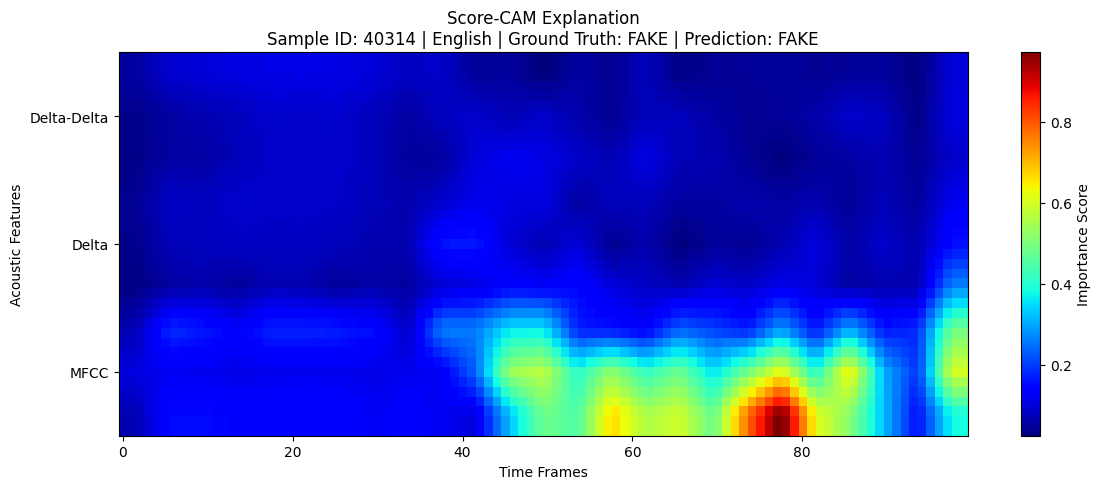

✅ English FAKE Score-CAM heatmap saved!
/content/drive/MyDrive/VocaTrust/Explainable_AI/ScoreCAM/Heatmaps/English_FAKE_Sample40314_ScoreCAM.png


In [ ]:
# ============================================================
# VISUALIZE AND SAVE ENGLISH FAKE SCORE-CAM
# ============================================================

sample_id = sample_info["Sample_ID"]

save_path = os.path.join(
    HEATMAP_DIR,
    f"English_FAKE_Sample{sample_id}_ScoreCAM.png"
)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap,
    aspect="auto",
    cmap="jet",
    origin="lower"
)

plt.colorbar(label="Importance Score")

plt.title(
    f"Score-CAM Explanation\n"
    f"Sample ID: {sample_id} | English | "
    f"Ground Truth: FAKE | Prediction: FAKE"
)

plt.xlabel("Time Frames")
plt.ylabel("Acoustic Features")

plt.yticks(
    [6, 19, 32],
    ["MFCC", "Delta", "Delta-Delta"]
)

plt.tight_layout()

#plt.savefig(
   # save_path,
   # dpi=300,
   # bbox_inches="tight"
#)

plt.show()

print("✅ English FAKE Score-CAM heatmap saved!")
print(save_path)

HINDI REAL

In [ ]:
# ============================================================
# SELECT HINDI REAL SAMPLE
# ============================================================

sample_index = 22449

sample_x = X_test[sample_index:sample_index + 1]
sample_y = y_test[sample_index]

sample_info = xai_metadata.iloc[sample_index]

print("Test Index   :", sample_index)
print("Sample ID    :", sample_info["Sample_ID"])
print("Language     :", sample_info["Language"])
print("Ground Truth :", sample_info["GroundTruth"])
print("Prediction   :", sample_info["Prediction"])
print("Probability REAL :", sample_info["Probability_REAL"])
print("Feature shape:", sample_x.shape)

Test Index   : 22449
Sample ID    : 98158
Language     : Hindi
Ground Truth : REAL
Prediction   : REAL
Probability REAL : 1.0
Feature shape: (1, 39, 100, 1)


In [ ]:
# ============================================================
# GENERATE HINDI REAL SCORE-CAM
# ============================================================

heatmap, prediction, target_class = score_cam(
    model=model,
    input_data=sample_x,
    target_layer_name="conv2d_2"
)

print("Original prediction:", prediction)
print("Target class:", "REAL" if target_class == 1 else "FAKE")
print("Heatmap shape:", heatmap.shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 39, 100, 1))
  warnings.warn(msg)


Original prediction: 1.0
Target class: REAL
Heatmap shape: (39, 100)


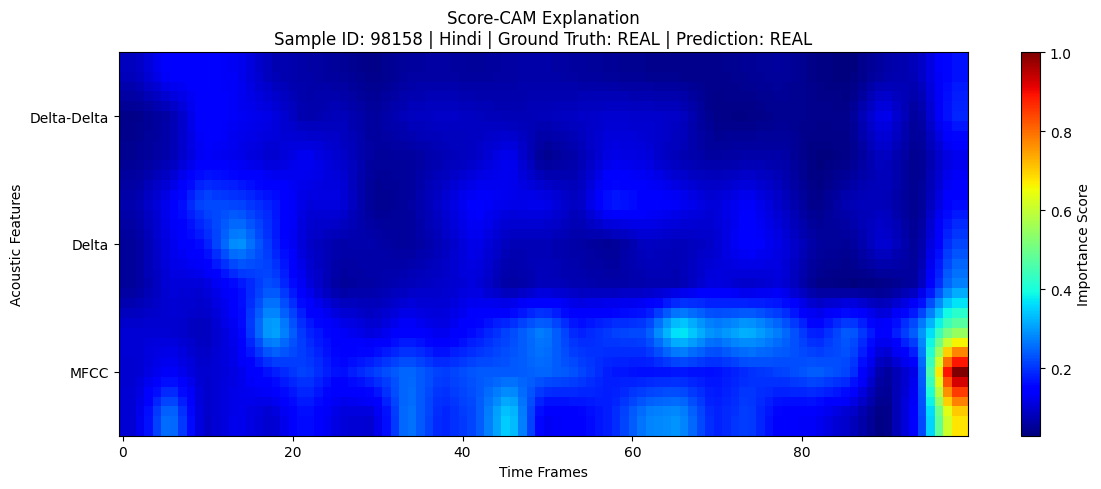

✅ Hindi REAL Score-CAM heatmap saved!
/content/drive/MyDrive/VocaTrust/Explainable_AI/ScoreCAM/Heatmaps/Hindi_REAL_Sample98158_ScoreCAM.png


In [ ]:
# ============================================================
# VISUALIZE AND SAVE HINDI REAL SCORE-CAM
# ============================================================

sample_id = sample_info["Sample_ID"]

save_path = os.path.join(
    HEATMAP_DIR,
    f"Hindi_REAL_Sample{sample_id}_ScoreCAM.png"
)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap,
    aspect="auto",
    cmap="jet",
    origin="lower"
)

plt.colorbar(label="Importance Score")

plt.title(
    f"Score-CAM Explanation\n"
    f"Sample ID: {sample_id} | Hindi | "
    f"Ground Truth: REAL | Prediction: REAL"
)

plt.xlabel("Time Frames")
plt.ylabel("Acoustic Features")

plt.yticks(
    [6, 19, 32],
    ["MFCC", "Delta", "Delta-Delta"]
)

plt.tight_layout()

#plt.savefig(
    #save_path,
    #dpi=300,
 #   bbox_inches="tight"
#)

plt.show()

print("✅ Hindi REAL Score-CAM heatmap saved!")
print(save_path)

HINDI FAKE

In [ ]:
# ============================================================
# SELECT HINDI FAKE SAMPLE
# ============================================================

sample_index = 2298

sample_x = X_test[sample_index:sample_index + 1]
sample_y = y_test[sample_index]

sample_info = xai_metadata.iloc[sample_index]

print("Test Index   :", sample_index)
print("Sample ID    :", sample_info["Sample_ID"])
print("Language     :", sample_info["Language"])
print("Ground Truth :", sample_info["GroundTruth"])
print("Prediction   :", sample_info["Prediction"])
print("Probability REAL :", sample_info["Probability_REAL"])
print("Feature shape:", sample_x.shape)

Test Index   : 2298
Sample ID    : 104028
Language     : Hindi
Ground Truth : FAKE
Prediction   : FAKE
Probability REAL : 7.7126346e-19
Feature shape: (1, 39, 100, 1)


In [ ]:
# ============================================================
# GENERATE HINDI FAKE SCORE-CAM
# ============================================================

heatmap, prediction, target_class = score_cam(
    model=model,
    input_data=sample_x,
    target_layer_name="conv2d_2"
)

print("Original prediction:", prediction)
print("Target class:", "REAL" if target_class == 1 else "FAKE")
print("Heatmap shape:", heatmap.shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 39, 100, 1))
  warnings.warn(msg)


Original prediction: 7.71237043557571e-19
Target class: FAKE
Heatmap shape: (39, 100)


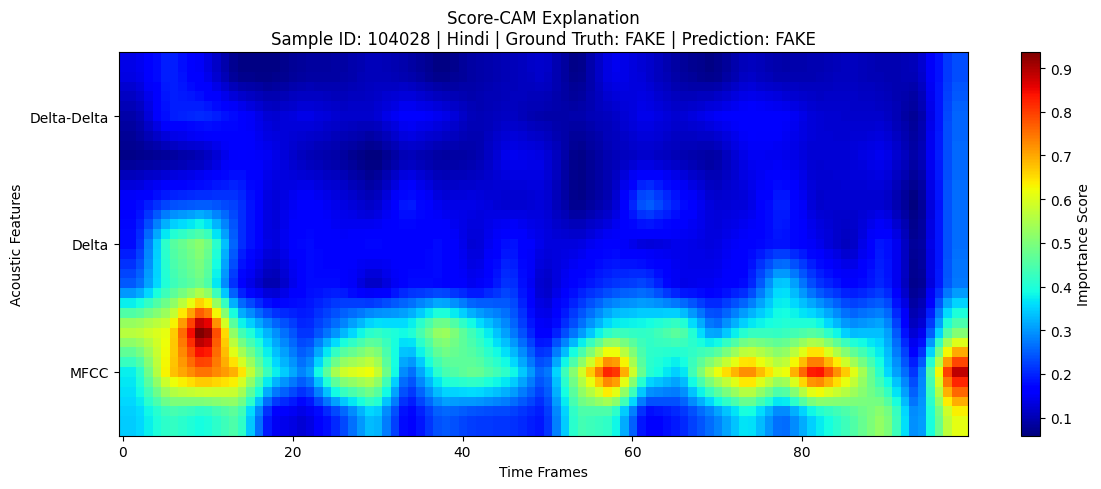

✅ Hindi FAKE Score-CAM heatmap saved!
/content/drive/MyDrive/VocaTrust/Explainable_AI/ScoreCAM/Heatmaps/Hindi_FAKE_Sample104028_ScoreCAM.png


In [ ]:
# ============================================================
# VISUALIZE AND SAVE HINDI FAKE SCORE-CAM
# ============================================================

sample_id = sample_info["Sample_ID"]

save_path = os.path.join(
    HEATMAP_DIR,
    f"Hindi_FAKE_Sample{sample_id}_ScoreCAM.png"
)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap,
    aspect="auto",
    cmap="jet",
    origin="lower"
)

plt.colorbar(label="Importance Score")

plt.title(
    f"Score-CAM Explanation\n"
    f"Sample ID: {sample_id} | Hindi | "
    f"Ground Truth: FAKE | Prediction: FAKE"
)

plt.xlabel("Time Frames")
plt.ylabel("Acoustic Features")

plt.yticks(
    [6, 19, 32],
    ["MFCC", "Delta", "Delta-Delta"]
)

plt.tight_layout()

#plt.savefig(
    #save_path,
    #dpi=300,
    #bbox_inches="tight"
#)

plt.show()

print("✅ Hindi FAKE Score-CAM heatmap saved!")
print(save_path)

VERIFY AND SAVING

In [ ]:
import os

print("Saved Score-CAM Heatmaps:\n")

for file in os.listdir(HEATMAP_DIR):
    if file.endswith(".png"):
        print("✅", file)

Saved Score-CAM Heatmaps:

✅ English_REAL_Sample2739_ScoreCAM.png
✅ English_FAKE_Sample40314_ScoreCAM.png
✅ Hindi_REAL_Sample98158_ScoreCAM.png
✅ Hindi_FAKE_Sample104028_ScoreCAM.png
✅ Hindi_REAL_Predicted_FAKE_Sample93035_ScoreCAM.png
✅ English_FAKE_Predicted_REAL_Sample70801_ScoreCAM.png


In [ ]:
# ============================================================
# SAVE SELECTED SCORE-CAM SAMPLE DETAILS
# ============================================================

selected_indices = [22685, 16787, 22449, 2298]

scorecam_samples = xai_metadata.iloc[selected_indices].copy()

scorecam_samples.insert(
    0,
    "Test_Index",
    selected_indices
)

display(scorecam_samples)

RESULTS_DIR = (
    "/content/drive/MyDrive/VocaTrust/"
    "Explainable_AI/ScoreCAM/Results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

scorecam_samples.to_csv(
    os.path.join(
        RESULTS_DIR,
        "ScoreCAM_Selected_Samples.csv"
    ),
    index=False
)

print("✅ Selected sample details saved!")

,Test_Index,Sample_ID,Language,GroundTruth,Dataset,Predicted_Label,Probability_REAL,Prediction,Correct
22685,22685,2739,English,REAL,Test,1,1.000000e+00,REAL,True
16787,16787,40314,English,FAKE,Test,0,1.314841e-23,FAKE,True
22449,22449,98158,Hindi,REAL,Test,1,1.000000e+00,REAL,True
2298,2298,104028,Hindi,FAKE,Test,0,7.712635e-19,FAKE,True


✅ Selected sample details saved!


ANALYZE MISCLASSIFIED TEST SAMPLES

In [ ]:
# ============================================================
# ANALYZE MISCLASSIFIED TEST SAMPLES
# ============================================================

incorrect_samples = xai_metadata[
    xai_metadata["Correct"] == False
].copy()

# Create error type
incorrect_samples["Error_Type"] = np.where(
    (incorrect_samples["GroundTruth"] == "REAL") &
    (incorrect_samples["Prediction"] == "FAKE"),
    "REAL predicted as FAKE",
    "FAKE predicted as REAL"
)

print("Total incorrect predictions:", len(incorrect_samples))

print("\nError type distribution:")
print(incorrect_samples["Error_Type"].value_counts())

print("\nErrors by language:")
print(
    pd.crosstab(
        incorrect_samples["Language"],
        incorrect_samples["Error_Type"]
    )
)

display(
    incorrect_samples[
        [
            "Sample_ID",
            "Language",
            "GroundTruth",
            "Prediction",
            "Probability_REAL",
            "Error_Type"
        ]
    ].head(20)
)

Total incorrect predictions: 191

Error type distribution:
Error_Type
REAL predicted as FAKE    101
FAKE predicted as REAL     90
Name: count, dtype: int64

Errors by language:
Error_Type  FAKE predicted as REAL  REAL predicted as FAKE
Language                                                  
English                         90                      43
Hindi                            0                      58


,Sample_ID,Language,GroundTruth,Prediction,Probability_REAL,Error_Type
162,101572,Hindi,REAL,FAKE,0.108427,REAL predicted as FAKE
195,49734,English,REAL,FAKE,0.430496,REAL predicted as FAKE
263,92069,Hindi,REAL,FAKE,0.063690,REAL predicted as FAKE
869,55298,English,REAL,FAKE,0.237683,REAL predicted as FAKE
1049,53936,English,REAL,FAKE,0.254942,REAL predicted as FAKE
1161,70801,English,FAKE,REAL,0.549749,FAKE predicted as REAL
1197,62579,English,REAL,FAKE,0.088477,REAL predicted as FAKE
1336,53214,English,REAL,FAKE,0.346983,REAL predicted as FAKE
1420,67745,English,FAKE,REAL,0.983391,FAKE predicted as REAL
1508,98546,Hindi,REAL,FAKE,0.451665,REAL predicted as FAKE


In [ ]:
# ============================================================
# SELECT REPRESENTATIVE MISCLASSIFIED SAMPLES
# ============================================================

error_indices = {
    "Hindi_REAL_predicted_FAKE": 1994,
    "English_FAKE_predicted_REAL": 1161
}

for error_name, index in error_indices.items():

    info = xai_metadata.iloc[index]

    print("\n" + "=" * 60)
    print(error_name)
    print("=" * 60)

    print("Test Index        :", index)
    print("Sample ID         :", info["Sample_ID"])
    print("Language          :", info["Language"])
    print("Ground Truth      :", info["GroundTruth"])
    print("Prediction        :", info["Prediction"])
    print("Probability REAL  :", info["Probability_REAL"])
    print("Correct           :", info["Correct"])


Hindi_REAL_predicted_FAKE
Test Index        : 1994
Sample ID         : 93035
Language          : Hindi
Ground Truth      : REAL
Prediction        : FAKE
Probability REAL  : 0.4964383
Correct           : False

English_FAKE_predicted_REAL
Test Index        : 1161
Sample ID         : 70801
Language          : English
Ground Truth      : FAKE
Prediction        : REAL
Probability REAL  : 0.5497486
Correct           : False


In [ ]:
# ============================================================
# SCORE-CAM: HINDI REAL PREDICTED AS FAKE
# ============================================================

sample_index = 1994

sample_x = X_test[sample_index:sample_index + 1]
sample_info = xai_metadata.iloc[sample_index]

print("Test Index   :", sample_index)
print("Sample ID    :", sample_info["Sample_ID"])
print("Language     :", sample_info["Language"])
print("Ground Truth :", sample_info["GroundTruth"])
print("Prediction   :", sample_info["Prediction"])
print("Probability REAL :", sample_info["Probability_REAL"])
print("Feature shape:", sample_x.shape)

# Generate Score-CAM
heatmap_error1, prediction_error1, target_class_error1 = score_cam(
    model=model,
    input_data=sample_x,
    target_layer_name="conv2d_2"
)

print("\nOriginal prediction:", prediction_error1)
print(
    "Target class:",
    "REAL" if target_class_error1 == 1 else "FAKE"
)
print("Heatmap shape:", heatmap_error1.shape)

Test Index   : 1994
Sample ID    : 93035
Language     : Hindi
Ground Truth : REAL
Prediction   : FAKE
Probability REAL : 0.4964383
Feature shape: (1, 39, 100, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 39, 100, 1))
  warnings.warn(msg)



Original prediction: 0.4964381456375122
Target class: FAKE
Heatmap shape: (39, 100)


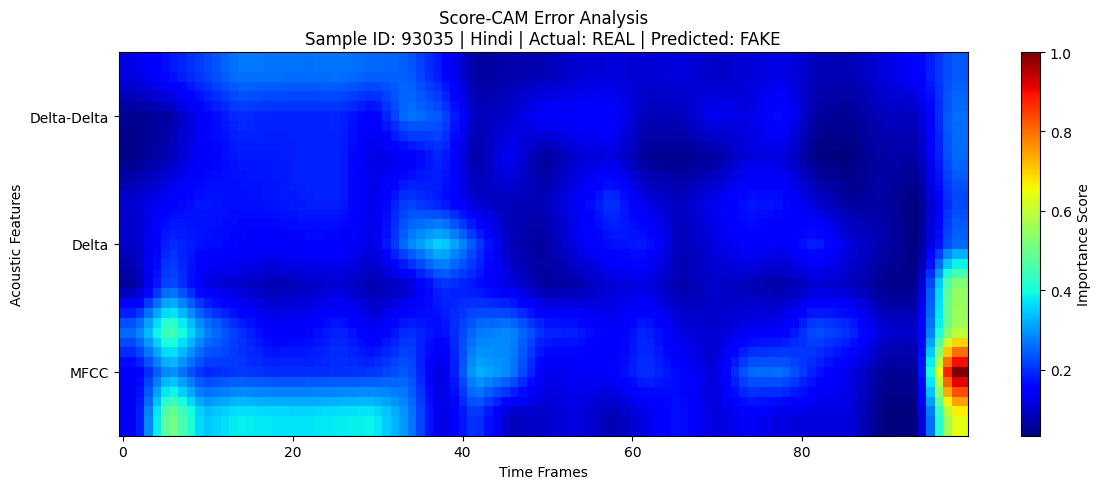

✅ Misclassification Score-CAM saved!
/content/drive/MyDrive/VocaTrust/Explainable_AI/ScoreCAM/Heatmaps/Hindi_REAL_Predicted_FAKE_Sample93035_ScoreCAM.png


In [ ]:
# ============================================================
# VISUALIZE SCORE-CAM
# HINDI REAL → PREDICTED AS FAKE
# ============================================================

sample_id = sample_info["Sample_ID"]

save_path = os.path.join(
    HEATMAP_DIR,
    f"Hindi_REAL_Predicted_FAKE_Sample{sample_id}_ScoreCAM.png"
)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap_error1,
    aspect="auto",
    cmap="jet",
    origin="lower"
)

plt.colorbar(label="Importance Score")

plt.title(
    f"Score-CAM Error Analysis\n"
    f"Sample ID: {sample_id} | Hindi | "
    f"Actual: REAL | Predicted: FAKE"
)

plt.xlabel("Time Frames")
plt.ylabel("Acoustic Features")

plt.yticks(
    [6, 19, 32],
    ["MFCC", "Delta", "Delta-Delta"]
)

plt.tight_layout()

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Misclassification Score-CAM saved!")
print(save_path)

In [ ]:
# ============================================================
# SCORE-CAM: ENGLISH FAKE PREDICTED AS REAL
# ============================================================

sample_index = 1161

sample_x = X_test[sample_index:sample_index + 1]
sample_info = xai_metadata.iloc[sample_index]

print("Test Index   :", sample_index)
print("Sample ID    :", sample_info["Sample_ID"])
print("Language     :", sample_info["Language"])
print("Ground Truth :", sample_info["GroundTruth"])
print("Prediction   :", sample_info["Prediction"])
print("Probability REAL :", sample_info["Probability_REAL"])
print("Feature shape:", sample_x.shape)

# Generate Score-CAM
heatmap_error2, prediction_error2, target_class_error2 = score_cam(
    model=model,
    input_data=sample_x,
    target_layer_name="conv2d_2"
)

print("\nOriginal prediction:", prediction_error2)
print(
    "Target class:",
    "REAL" if target_class_error2 == 1 else "FAKE"
)
print("Heatmap shape:", heatmap_error2.shape)

Test Index   : 1161
Sample ID    : 70801
Language     : English
Ground Truth : FAKE
Prediction   : REAL
Probability REAL : 0.5497486
Feature shape: (1, 39, 100, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 39, 100, 1))
  warnings.warn(msg)



Original prediction: 0.5497487187385559
Target class: REAL
Heatmap shape: (39, 100)


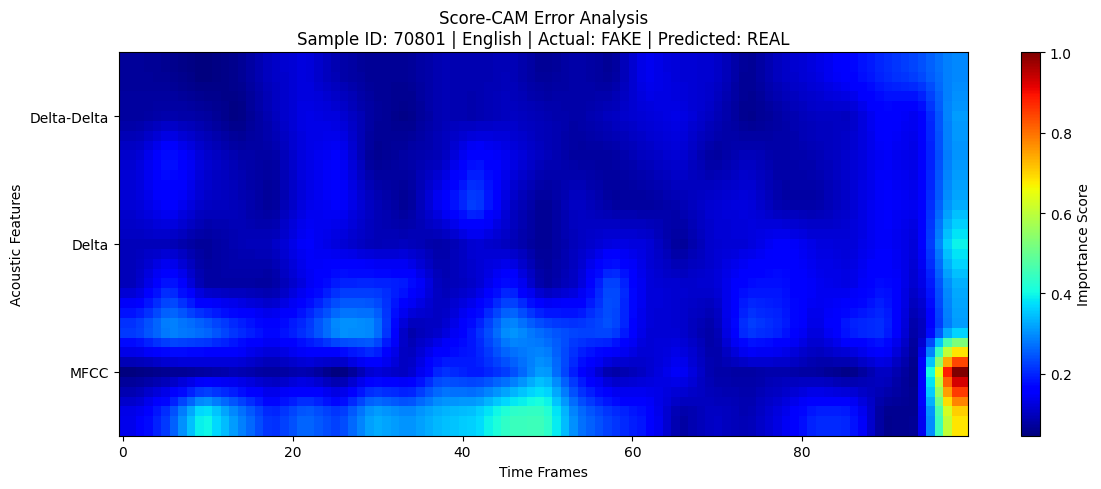

In [ ]:
# ============================================================
# VISUALIZE SCORE-CAM
# ENGLISH FAKE → PREDICTED AS REAL
# ============================================================

sample_id = sample_info["Sample_ID"]

save_path = os.path.join(
    HEATMAP_DIR,
    f"English_FAKE_Predicted_REAL_Sample{sample_id}_ScoreCAM.png"
)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap_error2,
    aspect="auto",
    cmap="jet",
    origin="lower"
)

plt.colorbar(label="Importance Score")

plt.title(
    f"Score-CAM Error Analysis\n"
    f"Sample ID: {sample_id} | English | "
    f"Actual: FAKE | Predicted: REAL"
)

plt.xlabel("Time Frames")
plt.ylabel("Acoustic Features")

plt.yticks(
    [6, 19, 32],
    ["MFCC", "Delta", "Delta-Delta"]
)

plt.tight_layout()

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Misclassification Score-CAM saved!")
print(save_path)

In [ ]:
# ============================================================
# VOCATRUST EXPLAINABLE AI REPORT FUNCTION
# ============================================================

import numpy as np

def generate_xai_report(
    heatmap,
    sample_info,
    prediction_probability,
    ground_truth=None
):

    # Prediction

if prediction_probability >= 0.5:
    prediction_label = "REAL"
else:
    prediction_label = "FAKE"

# Confidence = confidence in the predicted class
confidence = max(
    prediction_probability,
    1 - prediction_probability
) * 100

# Voice Integrity Score = probability that the voice is REAL
integrity_score = prediction_probability * 100

    # Risk level
    if integrity_score >= 80:
        risk_level = "Genuine"
    elif integrity_score >= 50:
        risk_level = "Suspicious"
    else:
        risk_level = "High Risk"

    # Heatmap statistics
    max_importance = float(np.max(heatmap))
    average_importance = float(np.mean(heatmap))
    std_importance = float(np.std(heatmap))

    # Feature groups
    mfcc_importance = np.mean(heatmap[0:13])
    delta_importance = np.mean(heatmap[13:26])
    delta2_importance = np.mean(heatmap[26:39])

    total = (
        mfcc_importance +
        delta_importance +
        delta2_importance
    )

    if total > 0:
        mfcc_percent = (mfcc_importance / total) * 100
        delta_percent = (delta_importance / total) * 100
        delta2_percent = (delta2_importance / total) * 100
    else:
        mfcc_percent = delta_percent = delta2_percent = 0

    # Important time regions
    time_importance = np.mean(heatmap, axis=0)

    threshold = 0.75 * np.max(time_importance)

    important_frames = np.where(
        time_importance >= threshold
    )[0]

    if len(important_frames) > 0:
        start_frame = int(important_frames.min())
        end_frame = int(important_frames.max())
        time_region = f"{start_frame} - {end_frame}"
    else:
        time_region = "Not detected"

    # Dominant feature
    contributions = {
        "MFCC": mfcc_percent,
        "Delta": delta_percent,
        "Delta-Delta": delta2_percent
    }

    dominant_feature = max(
        contributions,
        key=contributions.get
    )

    # Ground truth
    if ground_truth is None:
        ground_truth = sample_info["GroundTruth"]

    # Interpretation
    if prediction_label == "REAL":
        interpretation = (
            "The model classified this voice as GENUINE.\n"
            f"Score-CAM indicates that {dominant_feature} "
            "acoustic regions contributed most strongly "
            "to the REAL prediction."
        )
    else:
        interpretation = (
            "The model classified this voice as FAKE.\n"
            f"Score-CAM indicates that {dominant_feature} "
            "acoustic regions contributed most strongly "
            "to the FAKE prediction."
        )

    # Print report
    print("=" * 70)
    print("           VOCATRUST AI ANALYSIS REPORT")
    print("=" * 70)

    print(f"Sample ID             : {sample_info['Sample_ID']}")
    print(f"Language              : {sample_info['Language']}")
    print(f"Ground Truth          : {ground_truth}")
    print()

    print(f"Prediction            : {prediction_label}")
    print(f"Confidence            : {confidence:.2f}%")
    print(f"Voice Integrity Score : {integrity_score:.2f}/100")
    print(f"Risk Level            : {risk_level}")
    print()

    print("Heatmap Statistics")
    print("-" * 30)
    print(f"Maximum Importance    : {max_importance:.6f}")
    print(f"Average Importance    : {average_importance:.6f}")
    print(f"Standard Deviation    : {std_importance:.6f}")
    print()

    print("Feature Contribution")
    print("-" * 30)
    print(f"MFCC Contribution        : {mfcc_percent:.2f}%")
    print(f"Delta Contribution       : {delta_percent:.2f}%")
    print(f"Delta-Delta Contribution : {delta2_percent:.2f}%")
    print()

    print("Important Time Regions")
    print("-" * 30)
    print(f"Most Important Frames : {time_region}")
    print(f"Dominant Feature      : {dominant_feature}")
    print()

    print("Interpretation")
    print("-" * 30)
    print(interpretation)

    print("=" * 70)

SyntaxError: invalid syntax (2718700382.py, line 18)

In [ ]:
generate_xai_report(
    heatmap=heatmap,
    sample_info=sample_info,
    prediction_probability=prediction
)

           VOCATRUST AI ANALYSIS REPORT
Sample ID             : 2739
Language              : English
Ground Truth          : REAL

Prediction            : REAL
Confidence            : 100.00%
Voice Integrity Score : 100.00/100
Risk Level            : Genuine

Heatmap Statistics
------------------------------
Maximum Importance    : 1.000000
Average Importance    : 0.188716
Standard Deviation    : 0.123883

Feature Contribution
------------------------------
MFCC Contribution        : 50.76%
Delta Contribution       : 27.18%
Delta-Delta Contribution : 22.06%

Important Time Regions
------------------------------
Most Important Frames : 97 - 99
Dominant Feature      : MFCC

Interpretation
------------------------------
The model classified this voice as GENUINE.
Score-CAM indicates that MFCC acoustic regions contributed most strongly to the REAL prediction.


In [ ]:
# ============================================================
# VOCATRUST XAI - SELECT BY SAMPLE ID
# ============================================================

sample_id_to_test = 101659  # <-- CHANGE ONLY THIS VALUE

# Find the sample in the test metadata
matches = xai_metadata[
    xai_metadata["Sample_ID"] == sample_id_to_test
]

# Check whether Sample ID exists
if len(matches) == 0:
    print(f"❌ Sample ID {sample_id_to_test} was not found in the test set.")

elif len(matches) > 1:
    print(f"❌ Sample ID {sample_id_to_test} appears multiple times.")

else:
    # Get the exact test index
    sample_index = matches.index[0]

    # Get metadata
    sample_info = xai_metadata.loc[sample_index]

    # Get the corresponding feature sample
    sample_x = X_test[
        sample_index:sample_index + 1
    ]

    # Get actual label
    sample_y = y_test[sample_index]

    print("=" * 70)
    print("SELECTED TEST SAMPLE")
    print("=" * 70)

    print("Test Index        :", sample_index)
    print("Sample ID         :", sample_info["Sample_ID"])
    print("Language          :", sample_info["Language"])
    print("Ground Truth      :", sample_info["GroundTruth"])
    print("Prediction        :", sample_info["Prediction"])
    print("Probability REAL  :", sample_info["Probability_REAL"])
    print("Feature Shape     :", sample_x.shape)

    # --------------------------------------------------------
    # Run Score-CAM
    # --------------------------------------------------------

    heatmap, prediction, target_class = score_cam(
        model=model,
        input_data=sample_x,
        target_layer_name="conv2d_2"
    )

    print("\nScore-CAM generated successfully!")
    print("Target class:",
          "REAL" if target_class == 1 else "FAKE")
    print("Heatmap shape:", heatmap.shape)

    # --------------------------------------------------------
    # Generate the VocaTrust XAI report
    # --------------------------------------------------------

    generate_xai_report(
        heatmap=heatmap,
        sample_info=sample_info,
        prediction_probability=prediction
    )

SELECTED TEST SAMPLE
Test Index        : 0
Sample ID         : 101659
Language          : Hindi
Ground Truth      : REAL
Prediction        : REAL
Probability REAL  : 0.99979836
Feature Shape     : (1, 39, 100, 1)

Score-CAM generated successfully!
Target class: REAL
Heatmap shape: (39, 100)
           VOCATRUST AI ANALYSIS REPORT
Sample ID             : 101659
Language              : Hindi
Ground Truth          : REAL

Prediction            : REAL
Confidence            : 99.98%
Voice Integrity Score : 99.98/100
Risk Level            : Genuine

Heatmap Statistics
------------------------------
Maximum Importance    : 1.000000
Average Importance    : 0.129691
Standard Deviation    : 0.092261

Feature Contribution
------------------------------
MFCC Contribution        : 46.91%
Delta Contribution       : 28.70%
Delta-Delta Contribution : 24.40%

Important Time Regions
------------------------------
Most Important Frames : 97 - 99
Dominant Feature      : MFCC

Interpretation
--------------

           VOCATRUST AI ANALYSIS REPORT
Sample ID             : 101659
Language              : Hindi
Ground Truth          : REAL

Prediction            : REAL
Confidence            : 99.98%
Voice Integrity Score : 99.98/100
Risk Level            : Genuine

Heatmap Statistics
------------------------------
Maximum Importance    : 1.000000
Average Importance    : 0.129691
Standard Deviation    : 0.092261

Feature Contribution
------------------------------
MFCC Contribution        : 46.91%
Delta Contribution       : 28.70%
Delta-Delta Contribution : 24.40%

Important Time Regions
------------------------------
Most Important Frames : 97 - 99
Dominant Feature      : MFCC

Interpretation
------------------------------
The model classified this voice as GENUINE.
Score-CAM indicates that MFCC acoustic regions contributed most strongly to the REAL prediction.


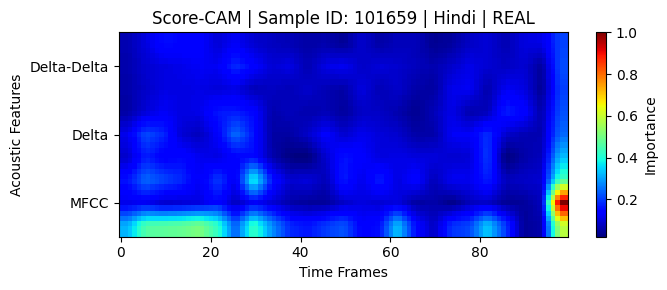

In [ ]:
# ============================================================
# VOCATRUST AI ANALYSIS
# SELECT SAMPLE ID + SCORE-CAM + SMALL HEATMAP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os


sample_id_to_test = 101659   # <-- CHANGE ONLY THIS


# ------------------------------------------------------------
# 1. Find Sample ID in test metadata
# ------------------------------------------------------------

matches = xai_metadata[
    xai_metadata["Sample_ID"] == sample_id_to_test
]

if len(matches) == 0:

    print(
        f"❌ Sample ID {sample_id_to_test} "
        "was not found in the test set."
    )

else:

    if len(matches) > 1:

        print(
            f"❌ Sample ID {sample_id_to_test} "
            "appears more than once."
        )

    else:

        # Exact test index
        sample_index = matches.index[0]

        # Metadata
        sample_info = xai_metadata.loc[sample_index]

        # Corresponding X_test feature
        sample_x = X_test[
            sample_index:sample_index + 1
        ]

        # Actual label
        sample_y = y_test[sample_index]


        # ----------------------------------------------------
        # 2. Generate Score-CAM
        # ----------------------------------------------------

        heatmap, prediction, target_class = score_cam(
            model=model,
            input_data=sample_x,
            target_layer_name="conv2d_2"
        )


        # ----------------------------------------------------
        # 3. Prediction information
        # ----------------------------------------------------

        if prediction >= 0.5:

    prediction_label = "REAL"

else:

    prediction_label = "FAKE"


# Confidence = confidence in the predicted class
confidence = max(
    prediction,
    1 - prediction
) * 100


# Voice Integrity Score = probability that the voice is REAL
integrity_score = prediction * 100

        # ----------------------------------------------------
        # 4. Risk level
        # ----------------------------------------------------

        if integrity_score >= 80:
            risk_level = "Genuine"

        elif integrity_score >= 50:
            risk_level = "Suspicious"

        else:
            risk_level = "High Risk"


        # ----------------------------------------------------
        # 5. Heatmap statistics
        # ----------------------------------------------------

        max_importance = float(
            np.max(heatmap)
        )

        average_importance = float(
            np.mean(heatmap)
        )

        std_importance = float(
            np.std(heatmap)
        )


        # ----------------------------------------------------
        # 6. Feature contribution
        # ----------------------------------------------------

        mfcc_importance = np.mean(
            heatmap[0:13]
        )

        delta_importance = np.mean(
            heatmap[13:26]
        )

        delta2_importance = np.mean(
            heatmap[26:39]
        )

        total = (
            mfcc_importance
            + delta_importance
            + delta2_importance
        )

        if total > 0:

            mfcc_percent = (
                mfcc_importance / total
            ) * 100

            delta_percent = (
                delta_importance / total
            ) * 100

            delta2_percent = (
                delta2_importance / total
            ) * 100

        else:

            mfcc_percent = 0
            delta_percent = 0
            delta2_percent = 0


        # ----------------------------------------------------
        # 7. Dominant feature
        # ----------------------------------------------------

        feature_contributions = {
            "MFCC": mfcc_percent,
            "Delta": delta_percent,
            "Delta-Delta": delta2_percent
        }

        dominant_feature = max(
            feature_contributions,
            key=feature_contributions.get
        )


        # ----------------------------------------------------
        # 8. Important time regions
        # ----------------------------------------------------

        time_importance = np.mean(
            heatmap,
            axis=0
        )

        threshold = (
            0.75 *
            np.max(time_importance)
        )

        important_frames = np.where(
            time_importance >= threshold
        )[0]

        if len(important_frames) > 0:

            start_frame = int(
                important_frames.min()
            )

            end_frame = int(
                important_frames.max()
            )

            time_region = (
                f"{start_frame} - {end_frame}"
            )

        else:

            time_region = "Not detected"


        # ----------------------------------------------------
        # 9. Interpretation
        # ----------------------------------------------------

        if prediction_label == "REAL":

            interpretation = (
                "The model classified this voice as GENUINE.\n"
                f"Score-CAM indicates that {dominant_feature} "
                "acoustic regions contributed most strongly "
                "to the REAL prediction."
            )

        else:

            interpretation = (
                "The model classified this voice as FAKE.\n"
                f"Score-CAM indicates that {dominant_feature} "
                "acoustic regions contributed most strongly "
                "to the FAKE prediction."
            )


        # ====================================================
        # 10. PRINT VOCATRUST REPORT
        # ====================================================

        print("=" * 70)
        print("           VOCATRUST AI ANALYSIS REPORT")
        print("=" * 70)

        print(
            f"Sample ID             : "
            f"{sample_info['Sample_ID']}"
        )

        print(
            f"Language              : "
            f"{sample_info['Language']}"
        )

        print(
            f"Ground Truth          : "
            f"{sample_info['GroundTruth']}"
        )

        print()

        print(
            f"Prediction            : "
            f"{prediction_label}"
        )

        print(
            f"Confidence            : "
            f"{confidence:.2f}%"
        )

        print(
            f"Voice Integrity Score : "
            f"{integrity_score:.2f}/100"
        )

        print(
            f"Risk Level            : "
            f"{risk_level}"
        )

        print()

        print("Heatmap Statistics")
        print("-" * 30)

        print(
            f"Maximum Importance    : "
            f"{max_importance:.6f}"
        )

        print(
            f"Average Importance    : "
            f"{average_importance:.6f}"
        )

        print(
            f"Standard Deviation    : "
            f"{std_importance:.6f}"
        )

        print()

        print("Feature Contribution")
        print("-" * 30)

        print(
            f"MFCC Contribution        : "
            f"{mfcc_percent:.2f}%"
        )

        print(
            f"Delta Contribution       : "
            f"{delta_percent:.2f}%"
        )

        print(
            f"Delta-Delta Contribution : "
            f"{delta2_percent:.2f}%"
        )

        print()

        print("Important Time Regions")
        print("-" * 30)

        print(
            f"Most Important Frames : "
            f"{time_region}"
        )

        print(
            f"Dominant Feature      : "
            f"{dominant_feature}"
        )

        print()

        print("Interpretation")
        print("-" * 30)

        print(interpretation)

        print("=" * 70)


        # ====================================================
        # 11. SMALL SCORE-CAM HEATMAP
        # ====================================================

        plt.figure(figsize=(7, 3))

        plt.imshow(
            heatmap,
            aspect="auto",
            cmap="jet",
            origin="lower"
        )

        plt.colorbar(
            label="Importance"
        )

        plt.title(
            f"Score-CAM | "
            f"Sample ID: {sample_info['Sample_ID']} | "
            f"{sample_info['Language']} | "
            f"{prediction_label}"
        )

        plt.xlabel(
            "Time Frames"
        )

        plt.ylabel(
            "Acoustic Features"
        )

        plt.yticks(
            [6, 19, 32],
            [
                "MFCC",
                "Delta",
                "Delta-Delta"
            ]
        )

        plt.tight_layout()

        plt.show()